In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.neighbors import NearestNeighbors

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
RANDOM_STATE = 42

print("Импорты загружены")

D:\Anaconda\envs\New_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Импорты загружены


In [2]:
# Загрузка Wine
wine_path = kagglehub.dataset_download("yasserh/wine-quality-dataset")
wine_file = [f for f in os.listdir(wine_path) if f.endswith('.csv')][0]
wine = pd.read_csv(os.path.join(wine_path, wine_file))

print(f"Wine размерность: {wine.shape}")

Wine размерность: (1143, 13)


In [3]:
# Загрузка Churn
churn_path = kagglehub.dataset_download("blastchar/telco-customer-churn")
churn_file = [f for f in os.listdir(churn_path) if f.endswith('.csv')][0]
churn = pd.read_csv(os.path.join(churn_path, churn_file))

print(f"Churn размерность: {churn.shape}")

Churn размерность: (7043, 21)


In [4]:
# Предобработка Wine
# Убираем целевую переменную quality
X_wine = wine.drop(columns=['quality', 'Id'])

scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine)

print(f"Wine после предобработки: {X_wine_scaled.shape}")
print(f"Признаки: {X_wine.columns.tolist()}")

Wine после предобработки: (1143, 11)
Признаки: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [5]:
# Предобработка Churn
churn = churn.copy()
churn = churn.drop(columns=['customerID', 'Churn'])  # убираем ID и целевую

# TotalCharges иногда строка с пробелами
churn['TotalCharges'] = pd.to_numeric(churn['TotalCharges'], errors='coerce')

numeric_features = churn.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = churn.select_dtypes(include=['object']).columns.tolist()

# ColumnTransformer: числовые — median + scaler, категориальные — most_frequent + OneHot
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_churn_scaled = preprocessor.fit_transform(churn)

print(f"Churn после предобработки: {X_churn_scaled.shape}")
print(f"Числовых: {len(numeric_features)}, Категориальных: {len(categorical_features)}")
print(f"После OneHot: {X_churn_scaled.shape[1]} столбцов")

Churn после предобработки: (7043, 30)
Числовых: 4, Категориальных: 15
После OneHot: 30 столбцов


## Подготовка данных

Для задачи кластеризации использованы **те же два датасета**, что в ЛР №4 и №5, но **с удалённой целевой переменной** — задача обучения без учителя не предполагает разметки.

| Датасет | Убрали | Признаков | После OneHot | Метод обработки |
|---|---|---|---|---|
| **Wine** | `quality`, `Id` | 11 числовых | 11 | StandardScaler |
| **Churn** | `customerID`, `Churn` | 4 числ + 15 кат | ~31 | ColumnTransformer + OneHot |

**Почему масштабирование критично:**
- K-Means минимизирует сумму квадратов **расстояний** до центроидов → если признак в диапазоне 0-10000, а другой в 0-1, второй не влияет на результат
- DBSCAN определяет плотность через **радиус окрестности** `eps` → без масштабирования eps не имеет смысла
- Иерархическая кластеризация использует **метрику расстояния** → та же проблема

**Почему Drop целевой переменной:**
Мы не знаем разметку в unsupervised — модель должна найти группы сама. Позже можно сравнить найденные кластеры с реальными классами для интерпретации.

## K-Means и метод локтя

### Что такое K-Means

**K-Means** — метрический алгоритм, который:
1. Выбирает `k` начальных центроидов
2. Каждую точку приписывает к **ближайшему** центроиду
3. Пересчитывает центроиды как среднее точек в кластере
4. Повторяет шаги 2-3 до сходимости

**Минимизирует inertia** — сумму квадратов расстояний точек до своих центроидов.

### Метод локтя

**Идея:** строим график inertia от `k`. Ищем точку, где inertia перестаёт быстро падать («локоть»). После неё добавление новых кластеров даёт мало пользы.

### Silhouette Score

Показывает, насколько точки похожи на свой кластер vs соседние:
- **1** — идеально (точка внутри кластера, далеко от соседей)
- **0** — на границе
- **-1** — точка приписана не туда

### PCA для визуализации

У нас 11 признаков (Wine) и ~31 (Churn). PCA сжимает до **2 компонент** для отображения на плоскости. Цифры в подписях осей показывают, сколько % дисперсии сохранила каждая компонента.

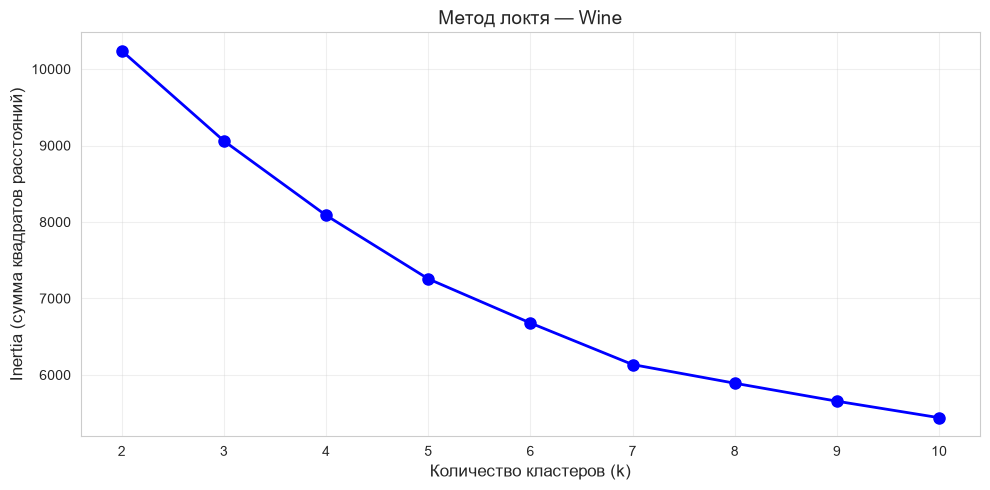

Inertia по k:
  k=2: inertia = 10238.49
  k=3: inertia = 9059.68
  k=4: inertia = 8086.80
  k=5: inertia = 7256.02
  k=6: inertia = 6678.65
  k=7: inertia = 6135.56
  k=8: inertia = 5891.27
  k=9: inertia = 5656.08
  k=10: inertia = 5440.39


In [6]:
# Метод локтя для Wine
inertias = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    kmeans.fit(X_wine_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Количество кластеров (k)', fontsize=12)
plt.ylabel('Inertia (сумма квадратов расстояний)', fontsize=12)
plt.title('Метод локтя — Wine', fontsize=14)
plt.grid(alpha=0.3)
plt.xticks(K_range)
plt.tight_layout()
plt.show()

# Выводим значения
print("Inertia по k:")
for k, inertia in zip(K_range, inertias):
    print(f"  k={k}: inertia = {inertia:.2f}")

In [13]:
# K-Means на Wine
K_WINE = 7

kmeans_wine = KMeans(n_clusters=K_WINE, random_state=RANDOM_STATE, n_init=10)
labels_kmeans_wine = kmeans_wine.fit_predict(X_wine_scaled)

print(f"K-Means на Wine (k={K_WINE}):")
print(f"  Inertia: {kmeans_wine.inertia_:.2f}")
print(f"  Silhouette Score: {silhouette_score(X_wine_scaled, labels_kmeans_wine):.4f}")
print(f"\nРаспределение по кластерам:")
print(pd.Series(labels_kmeans_wine).value_counts().sort_index())

K-Means на Wine (k=7):
  Inertia: 6135.56
  Silhouette Score: 0.1955

Распределение по кластерам:
0    365
1     19
2    125
3    242
4     31
5    182
6    179
Name: count, dtype: int64


PCA объясняет 45.8% дисперсии


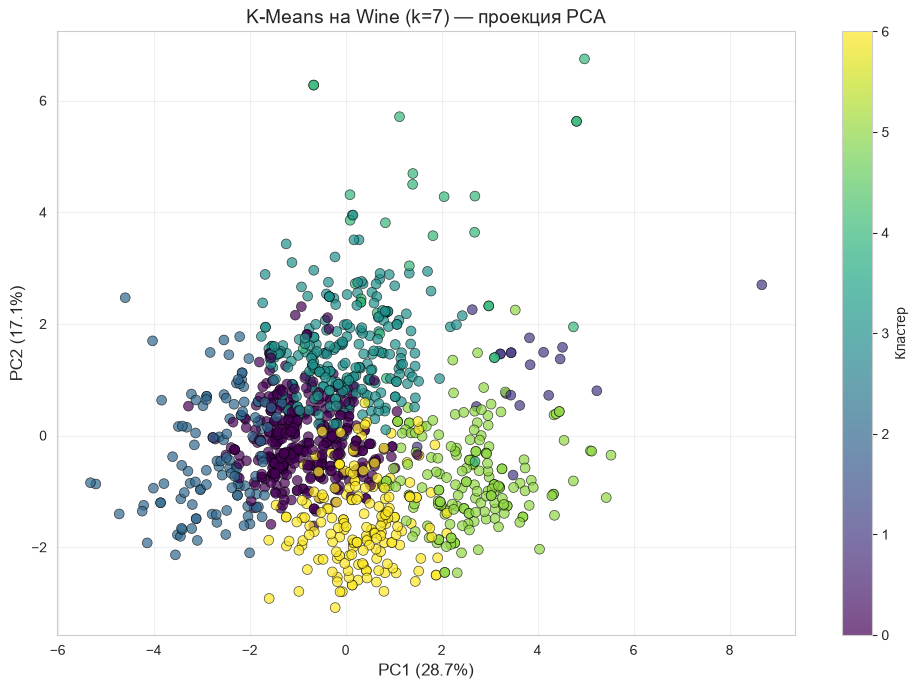

In [14]:
# PCA + визуализация K-Means (Wine)
pca_wine = PCA(n_components=2, random_state=RANDOM_STATE)
X_wine_pca = pca_wine.fit_transform(X_wine_scaled)

print(f"PCA объясняет {pca_wine.explained_variance_ratio_.sum()*100:.1f}% дисперсии")

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1],
                       c=labels_kmeans_wine, cmap='viridis',
                       s=50, alpha=0.7, edgecolor='k', linewidth=0.5)
plt.xlabel(f'PC1 ({pca_wine.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'PC2 ({pca_wine.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
plt.title(f'K-Means на Wine (k={K_WINE}) — проекция PCA', fontsize=14)
plt.colorbar(scatter, label='Кластер')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

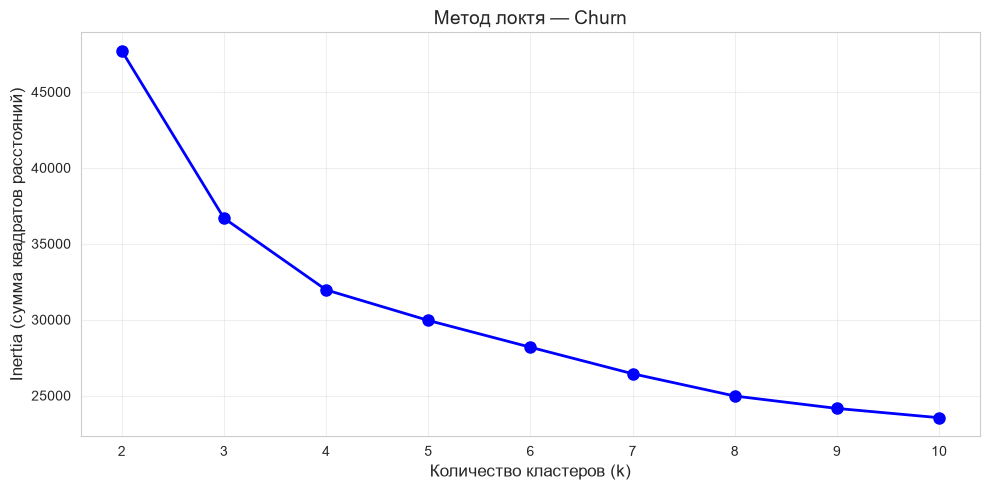

Inertia по k:
  k=2: inertia = 47703.29
  k=3: inertia = 36683.90
  k=4: inertia = 31959.42
  k=5: inertia = 29948.07
  k=6: inertia = 28182.10
  k=7: inertia = 26437.15
  k=8: inertia = 24969.30
  k=9: inertia = 24152.48
  k=10: inertia = 23541.19


In [10]:
# Метод локтя для Churn
inertias_c = []
K_range_c = range(2, 11)

for k in K_range_c:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    kmeans.fit(X_churn_scaled)
    inertias_c.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(K_range_c, inertias_c, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Количество кластеров (k)', fontsize=12)
plt.ylabel('Inertia (сумма квадратов расстояний)', fontsize=12)
plt.title('Метод локтя — Churn', fontsize=14)
plt.grid(alpha=0.3)
plt.xticks(K_range_c)
plt.tight_layout()
plt.show()

print("Inertia по k:")
for k, inertia in zip(K_range_c, inertias_c):
    print(f"  k={k}: inertia = {inertia:.2f}")

In [11]:
# K-Means на Churn
K_CHURN = 3

kmeans_churn = KMeans(n_clusters=K_CHURN, random_state=RANDOM_STATE, n_init=10)
labels_kmeans_churn = kmeans_churn.fit_predict(X_churn_scaled)

print(f"K-Means на Churn (k={K_CHURN}):")
print(f"  Inertia: {kmeans_churn.inertia_:.2f}")
print(f"  Silhouette Score: {silhouette_score(X_churn_scaled, labels_kmeans_churn):.4f}")
print(f"\nРаспределение по кластерам:")
print(pd.Series(labels_kmeans_churn).value_counts().sort_index())

K-Means на Churn (k=3):
  Inertia: 36683.90
  Silhouette Score: 0.2621

Распределение по кластерам:
0    2271
1    1526
2    3246
Name: count, dtype: int64


PCA объясняет 53.4% дисперсии


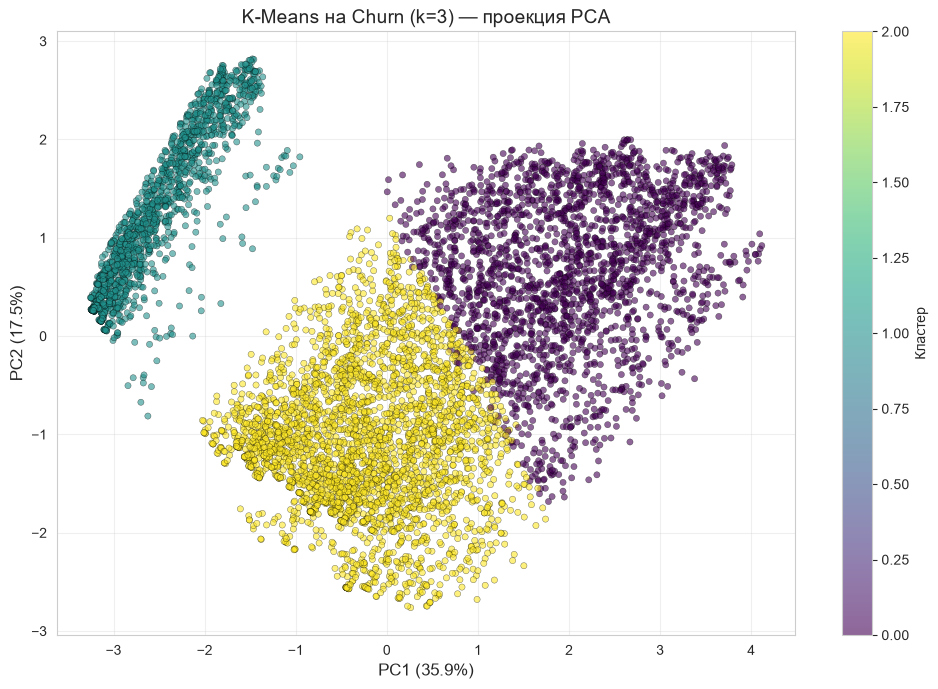

In [12]:
# PCA + визуализация K-Means (Churn)
pca_churn = PCA(n_components=2, random_state=RANDOM_STATE)
X_churn_pca = pca_churn.fit_transform(X_churn_scaled)

print(f"PCA объясняет {pca_churn.explained_variance_ratio_.sum()*100:.1f}% дисперсии")

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_churn_pca[:, 0], X_churn_pca[:, 1],
                       c=labels_kmeans_churn, cmap='viridis',
                       s=20, alpha=0.6, edgecolor='k', linewidth=0.3)
plt.xlabel(f'PC1 ({pca_churn.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'PC2 ({pca_churn.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
plt.title(f'K-Means на Churn (k={K_CHURN}) — проекция PCA', fontsize=14)
plt.colorbar(scatter, label='Кластер')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## K-Means и метод локтя

### Метод локтя — Wine

**Вывод:** локоть на **k=7**. От k=6 до k=7 inertia падает на 543, а от k=7 до k=8 — только на 245. После 7-го кластера добавление новых даёт минимальный выигрыш.

### Метод локтя — Churn

**Вывод:** локоть на **k=3**. От k=2 до k=3 inertia падает на 11 019, а от k=3 до k=4 — только на 4 725.

### Результаты K-Means

| Датасет | k | Inertia | Silhouette | Распределение |
|---|---|---|---|---|
| **Wine** | 7 | 6135.56 | **0.1955** | 365 / 19 / 125 / 242 / 31 / 182 / 179 |
| **Churn** | 3 | 36683.90 | **0.2621** | 2271 / 1526 / 3246 |

### Интерпретация

**Wine (k=7, silhouette 0.1955):**
- Silhouette низкий (< 0.25) — структура слабая, но это ожидаемо для непрерывной шкалы качества вина (3-8). Чётких границ между «плохим» и «средним» вином нет.
- Кластеры сильно разного размера (от 19 до 365 точек) — K-Means нашёл неоднородную структуру: есть «плотные» группы и редкие точки.

**Churn (k=3, silhouette 0.2621):**
- Silhouette чуть выше, но всё ещё слабый (0.25–0.5 = «слабая структура»).
- Причина: после OneHotEncoder у нас ~31 бинарных признаков. В таком высокоразмерном пространстве расстояния становятся «размытыми» — это **проклятие размерности**.
- Кластеры относительно сбалансированы (2271 / 1526 / 3246) — что логично: клиенты делятся на лояльных, уходящих и «промежуточных».

**Почему silhouette низкий — это не провал:**
- K-Means всегда строит `k` кластеров, даже если структуры нет
- Низкий silhouette говорит: «данные слабо разделяются на группы»
- Для Wine и Churn это **ожидаемо** — обе задачи лучше решаются с учителем (классификация), а кластеризация — это исследование структуры

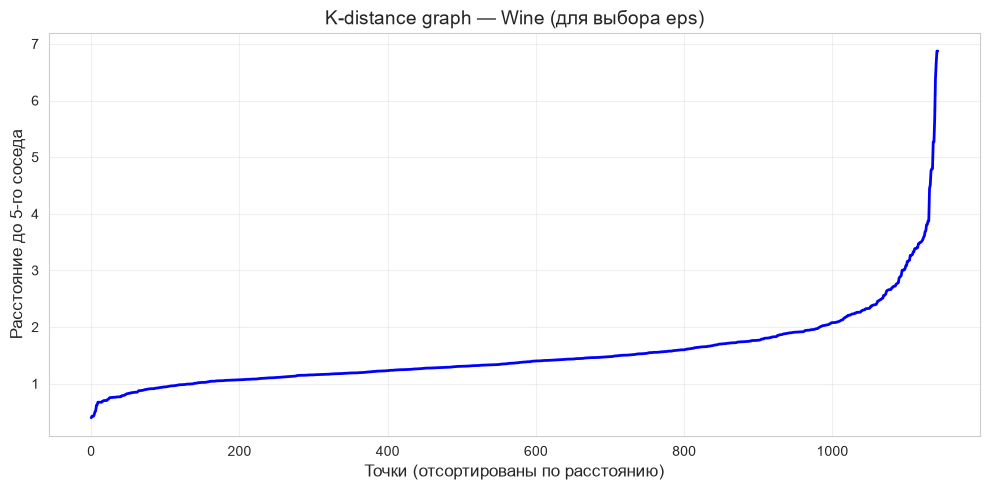

min_distance: 0.40
max_distance: 6.87
median:       1.36
90-й перцентиль: 2.23


In [15]:
# K-distance graph — подбор eps для Wine
from sklearn.neighbors import NearestNeighbors

# Для каждого объекта считаем расстояние до k-го соседа
k_neighbors = 5  # min_samples - 1
nn = NearestNeighbors(n_neighbors=k_neighbors)
nn.fit(X_wine_scaled)
distances, _ = nn.kneighbors(X_wine_scaled)

# Сортируем расстояния и строим график
distances_sorted = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(distances_sorted, 'b-', linewidth=2)
plt.xlabel('Точки (отсортированы по расстоянию)', fontsize=12)
plt.ylabel(f'Расстояние до {k_neighbors}-го соседа', fontsize=12)
plt.title('K-distance graph — Wine (для выбора eps)', fontsize=14)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"min_distance: {distances_sorted.min():.2f}")
print(f"max_distance: {distances_sorted.max():.2f}")
print(f"median:       {np.median(distances_sorted):.2f}")
print(f"90-й перцентиль: {np.percentile(distances_sorted, 90):.2f}")

In [16]:
# DBSCAN на Wine
EPS_WINE = 2.5
MIN_SAMPLES_WINE = 5

dbscan_wine = DBSCAN(eps=EPS_WINE, min_samples=MIN_SAMPLES_WINE)
labels_dbscan_wine = dbscan_wine.fit_predict(X_wine_scaled)

n_clusters = len(set(labels_dbscan_wine)) - (1 if -1 in labels_dbscan_wine else 0)
n_noise = list(labels_dbscan_wine).count(-1)

print(f"DBSCAN на Wine (eps={EPS_WINE}, min_samples={MIN_SAMPLES_WINE}):")
print(f"  Кластеров: {n_clusters}")
print(f"  Шумовых точек (-1): {n_noise} ({n_noise/len(labels_dbscan_wine)*100:.1f}%)")
print(f"\nРаспределение:")
print(pd.Series(labels_dbscan_wine).value_counts().sort_index())

DBSCAN на Wine (eps=2.5, min_samples=5):
  Кластеров: 2
  Шумовых точек (-1): 55 (4.8%)

Распределение:
-1      55
 0    1079
 1       9
Name: count, dtype: int64


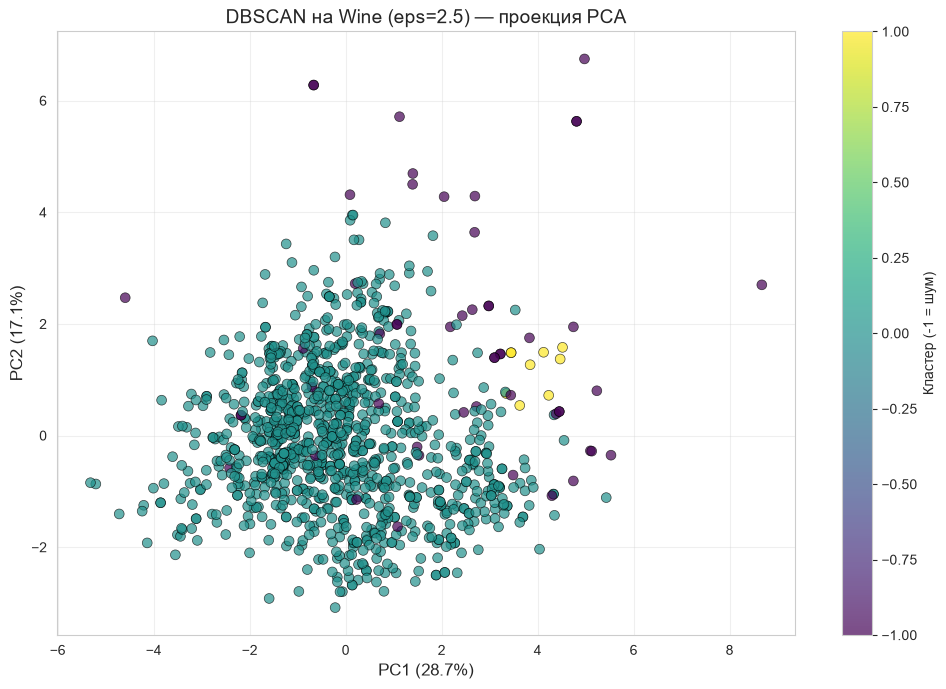

In [17]:
# Визуализация DBSCAN (Wine)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1],
                       c=labels_dbscan_wine, cmap='viridis',
                       s=50, alpha=0.7, edgecolor='k', linewidth=0.5)
plt.xlabel(f'PC1 ({pca_wine.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'PC2 ({pca_wine.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
plt.title(f'DBSCAN на Wine (eps={EPS_WINE}) — проекция PCA', fontsize=14)
plt.colorbar(scatter, label='Кластер (-1 = шум)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

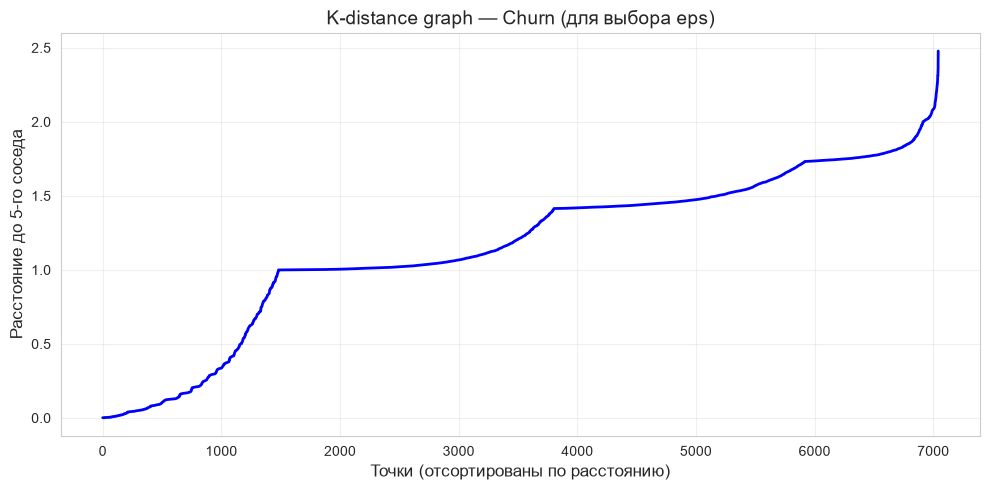

min_distance: 0.00
max_distance: 2.48
median:       1.22
90-й перцентиль: 1.76


In [18]:
# K-distance graph — подбор eps для Churn
nn_c = NearestNeighbors(n_neighbors=k_neighbors)
nn_c.fit(X_churn_scaled)
distances_c, _ = nn_c.kneighbors(X_churn_scaled)

distances_c_sorted = np.sort(distances_c[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(distances_c_sorted, 'b-', linewidth=2)
plt.xlabel('Точки (отсортированы по расстоянию)', fontsize=12)
plt.ylabel(f'Расстояние до {k_neighbors}-го соседа', fontsize=12)
plt.title('K-distance graph — Churn (для выбора eps)', fontsize=14)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"min_distance: {distances_c_sorted.min():.2f}")
print(f"max_distance: {distances_c_sorted.max():.2f}")
print(f"median:       {np.median(distances_c_sorted):.2f}")
print(f"90-й перцентиль: {np.percentile(distances_c_sorted, 90):.2f}")

In [19]:
# DBSCAN на Churn
EPS_CHURN = 2.0
MIN_SAMPLES_CHURN = 5

dbscan_churn = DBSCAN(eps=EPS_CHURN, min_samples=MIN_SAMPLES_CHURN)
labels_dbscan_churn = dbscan_churn.fit_predict(X_churn_scaled)

n_clusters_c = len(set(labels_dbscan_churn)) - (1 if -1 in labels_dbscan_churn else 0)
n_noise_c = list(labels_dbscan_churn).count(-1)

print(f"DBSCAN на Churn (eps={EPS_CHURN}, min_samples={MIN_SAMPLES_CHURN}):")
print(f"  Кластеров: {n_clusters_c}")
print(f"  Шумовых точек (-1): {n_noise_c} ({n_noise_c/len(labels_dbscan_churn)*100:.1f}%)")
print(f"\nРаспределение:")
print(pd.Series(labels_dbscan_churn).value_counts().sort_index())

DBSCAN на Churn (eps=2.0, min_samples=5):
  Кластеров: 4
  Шумовых точек (-1): 29 (0.4%)

Распределение:
-1      29
 0    4425
 1    1474
 2    1063
 3      52
Name: count, dtype: int64


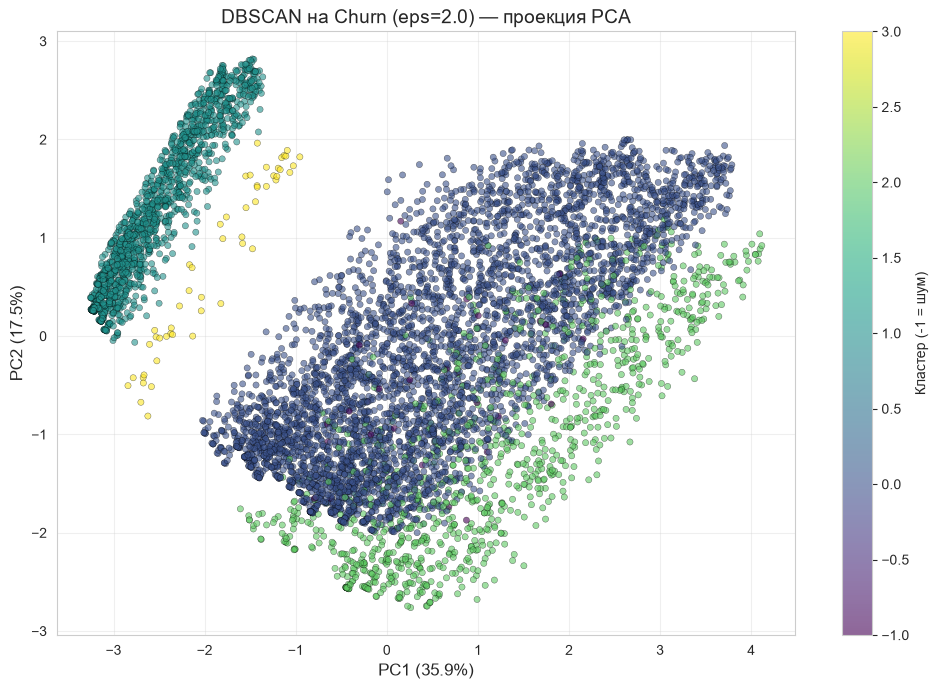

In [20]:
# Визуализация DBSCAN (Churn)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_churn_pca[:, 0], X_churn_pca[:, 1],
                       c=labels_dbscan_churn, cmap='viridis',
                       s=20, alpha=0.6, edgecolor='k', linewidth=0.3)
plt.xlabel(f'PC1 ({pca_churn.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'PC2 ({pca_churn.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
plt.title(f'DBSCAN на Churn (eps={EPS_CHURN}) — проекция PCA', fontsize=14)
plt.colorbar(scatter, label='Кластер (-1 = шум)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## DBSCAN — плотностной подход

### Что такое DBSCAN

**DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** — алгоритм, который ищет **плотные области** в пространстве и объединяет точки, находящиеся близко друг к другу.

**Как работает:**
1. Для каждой точки смотрит, сколько соседей в радиусе `eps`
2. Если соседей ≥ `min_samples` — точка «ядровая»
3. Ядровые точки и их соседи объединяются в кластер
4. Точки, не попавшие ни в один кластер — **шум** (метка `-1`)

**Ключевые параметры:**
- `eps` — радиус окрестности (в единицах масштабированного пространства)
- `min_samples` — минимум точек в окрестности для «плотной» области

### Подбор eps через k-distance graph

Строим график: для каждой точки — расстояние до 5-го соседа (отсортированное). Ищем **локоть** — там `eps` оптимален.

- Слишком маленький `eps` → почти все точки шум
- Слишком большой `eps` → все точки сливаются в 1 кластер

### Результаты

| Датасет | eps | min_samples | Кластеров | Шум |
|---|---|---|---|---|
| Wine | 2.5 | 5 | 2 | 4.8% |
| Churn | 2.0 | 5 | 4 | 0.4% |


### Отличие от K-Means

| | K-Means | DBSCAN |
|---|---|---|
| Форма кластеров | Сферическая | **Любая** (по плотности) |
| Число кластеров | Задаём вручную (`k`) | **Определяется автоматически** |
| Шум | Нет | **Есть** (метка -1) |
| Чувствительность к eps | Нет | **Высокая** |
| Скорость | Быстрый | Медленнее на больших данных |

**Ключевое преимущество DBSCAN:** не требует задавать число кластеров и умеет находить кластеры произвольной формы.

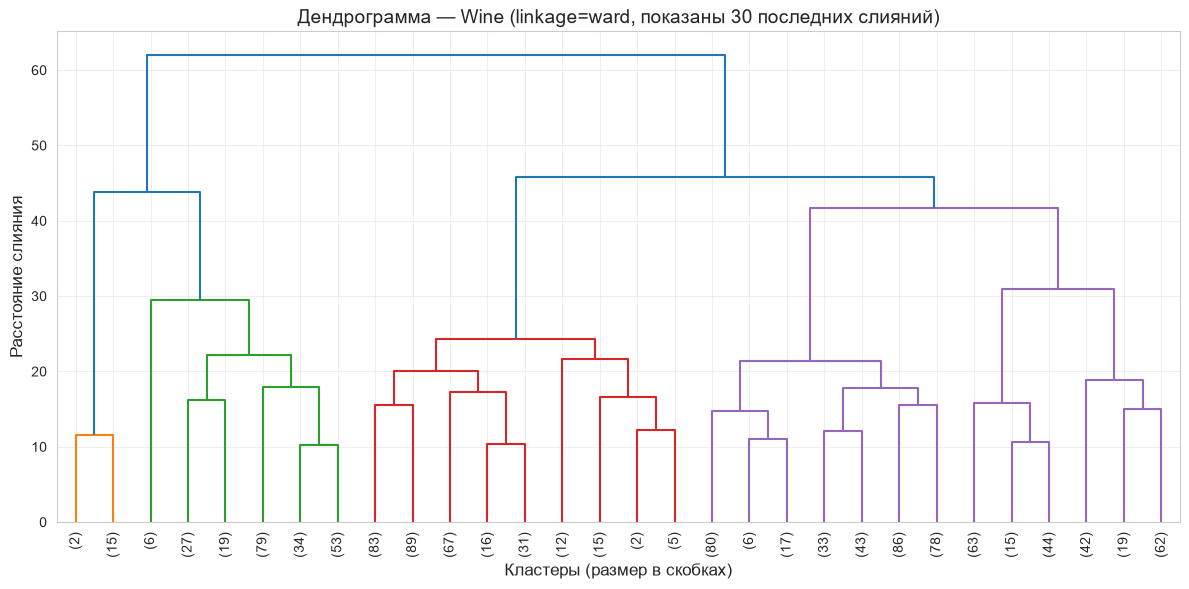

Форма матрицы Z_wine: (1142, 4)


In [21]:
# Считаем матрицу связей (linkage) на Wine
Z_wine = linkage(X_wine_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z_wine, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)
plt.title('Дендрограмма — Wine (linkage=ward, показаны 30 последних слияний)', fontsize=14)
plt.xlabel('Кластеры (размер в скобках)', fontsize=12)
plt.ylabel('Расстояние слияния', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Форма матрицы Z_wine: {Z_wine.shape}")

In [22]:
# Обучаем иерархическую кластеризацию на Wine
K_WINE_HC = 7  # по аналогии с локтем K-Means

hc_wine = AgglomerativeClustering(n_clusters=K_WINE_HC, linkage='ward')
labels_hc_wine = hc_wine.fit_predict(X_wine_scaled)

sil_hc_wine = silhouette_score(X_wine_scaled, labels_hc_wine)

print(f"AgglomerativeClustering на Wine (k={K_WINE_HC}, linkage='ward'):")
print(f"  Silhouette Score: {sil_hc_wine:.4f}")
print(f"\nРаспределение по кластерам:")
print(pd.Series(labels_hc_wine).value_counts().sort_index())

AgglomerativeClustering на Wine (k=7, linkage='ward'):
  Silhouette Score: 0.1460

Распределение по кластерам:
0    320
1    343
2    212
3     17
4    123
5    122
6      6
Name: count, dtype: int64


## Иерархическая кластеризация — Wine

### Дендрограмма

Дендрограмма построена с `linkage='ward'` (минимизирует внутрикластерную дисперсию, работает с евклидовой метрикой — оптимальный выбор для числовых признаков без выбросов). Для читаемости отображены только **30 последних слияний** (`truncate_mode='lastp'`), поддеревья подписаны размером кластера в скобках.

**Чтение дендрограммы:**
- По оси Y — расстояние слияния. Чем выше точка слияния, тем более «разные» группы объединяются.
- Виден **явный скачок на высоте ~60**: на этом уровне дерево делится на два больших поддерева (высота 44 и 46). Если «резать» дерево здесь — получим **2 кластера**.
- Внутри правого поддерева (высота 46) есть ещё один заметный скачок на высоте ~42 → деление на две группы.
- На более низких уровнях (высота 15–30) идут плавные слияния — **чёткой иерархии для k=7 не видно**, расстояния слияния монотонно убывают, без выраженных «полок».

**Вывод:** дендрограмма указывает на **естественную структуру из 2 (максимум 3–4) кластеров**, а не из 7. Это подтверждает, что Wine — это непрерывный спектр, а не дискретные группы.

### AgglomerativeClustering (k=7, linkage='ward')

| Метрика | Значение |
|---|---|
| **Silhouette Score** | **0.1460** |
| Размеры кластеров | 320 / 343 / 212 / 17 / 123 / 122 / **6** |

**Сравнение с K-Means (k=7):**

| Алгоритм | Silhouette | Размеры кластеров |
|---|---|---|
| K-Means | 0.1955 | 365 / 19 / 125 / 242 / 31 / 182 / 179 |
| Agglomerative (ward) | **0.1460** | 320 / 343 / 212 / 17 / 123 / 122 / **6** |

### Интерпретация

1. **Silhouette ниже, чем у K-Means** (0.1460 vs 0.1955). Это ожидаемо: `ward` минимизирует дисперсию **иерархически**, а не глобально, как K-Means. На «плоских» данных без явной структуры K-Means обычно находит чуть лучшую разбивку по silhouette.

2. **Появился крошечный кластер из 6 точек** — это типичная проблема AgglomerativeClustering при `ward`: алгоритм не «перераспределяет» точки между кластерами после слияния, поэтому легко оставляет изолированные группы. K-Means в этом смысле сбалансированнее.

3. **Оба silhouette < 0.25** — оба алгоритма подтверждают: **у Wine нет чёткой кластерной структуры** (непрерывная шкала качества 3–8). Разница между алгоритмами — это разница в способе проведения границ, а не признак «правильности».

4. **Практический вывод:** если нужно сегментировать вина, иерархия с k=2–3 по дендрограмме может быть осмысленнее, чем k=7 (локоть K-Means). k=7 — это артефакт «уменьшения inertia», а не реальная структура.

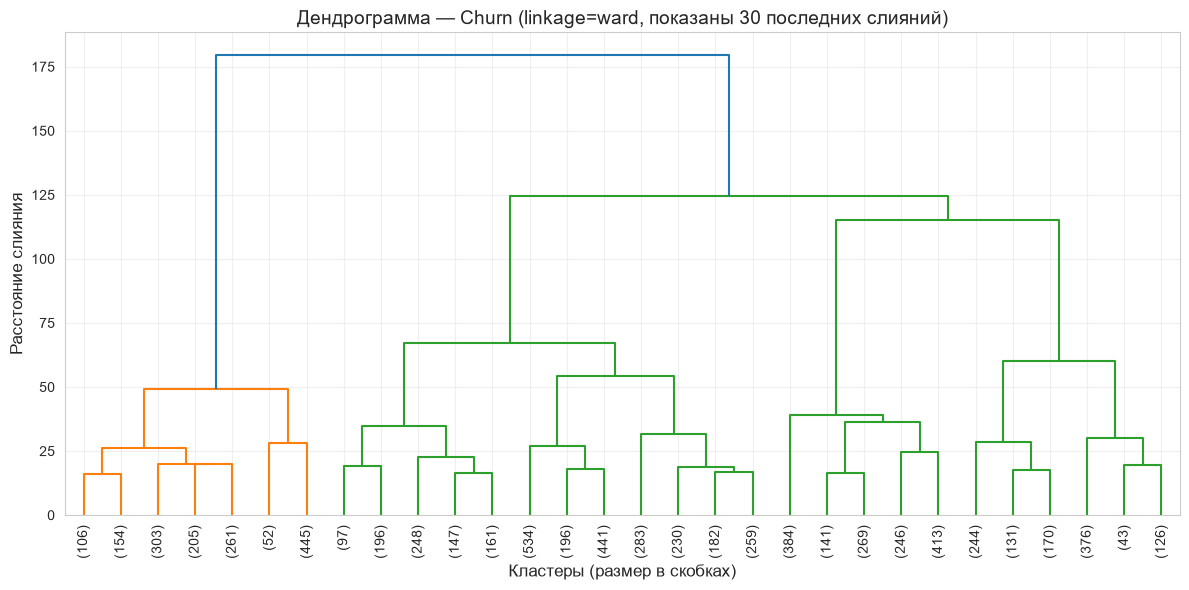

Форма матрицы Z_churn: (7042, 4)


In [23]:
# Дендрограмма для Churn
Z_churn = linkage(X_churn_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z_churn, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)
plt.title('Дендрограмма — Churn (linkage=ward, показаны 30 последних слияний)', fontsize=14)
plt.xlabel('Кластеры (размер в скобках)', fontsize=12)
plt.ylabel('Расстояние слияния', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Форма матрицы Z_churn: {Z_churn.shape}")

In [24]:
# Обучаем иерархическую кластеризацию на Churn
K_CHURN_HC = 3  # по аналогии с локтем K-Means

hc_churn = AgglomerativeClustering(n_clusters=K_CHURN_HC, linkage='ward')
labels_hc_churn = hc_churn.fit_predict(X_churn_scaled)

sil_hc_churn = silhouette_score(X_churn_scaled, labels_hc_churn)

print(f"AgglomerativeClustering на Churn (k={K_CHURN_HC}, linkage='ward'):")
print(f"  Silhouette Score: {sil_hc_churn:.4f}")
print(f"\nРаспределение по кластерам:")
print(pd.Series(labels_hc_churn).value_counts().sort_index())

AgglomerativeClustering на Churn (k=3, linkage='ward'):
  Silhouette Score: 0.2194

Распределение по кластерам:
0    2543
1    1526
2    2974
Name: count, dtype: int64


## Иерархическая кластеризация — Churn

### Дендрограмма

Дендрограмма построена с `linkage='ward'` на ~30 признаках после OneHotEncoder. Отображены **30 последних слияний**, поддеревья подписаны размером.

**Чтение дендрограммы:**
- На самой вершине (высота ~180) — **глобальный скачок**, разделяющий данные на **2 больших поддерева**: одно (оранжевое) на высоте 50 объединяет несколько кластеров размером 106–445; второе (зелёное) на высоте 125 — более крупную ветвь с кластерами 97–534.
- Внутри зелёной ветви виден ещё один выраженный скачок на высоте ~112 → деление на две части. Итого: **естественная структура — 3 кластера** (что совпадает с локтем K-Means!).
- Внутри каждого из трёх блоков слияния плавные, на высоте 15–40 — мелкая структура.

**Вывод:** дендрограмма поддерживает **k=3** как осмысленный уровень разбиения (совпадает с локтем K-Means — сильный аргумент). Для k=4–5 тоже есть основания (скачки на 50–60), но k=3 — самый «чистый».

### AgglomerativeClustering (k=3, linkage='ward')

| Метрика | Значение |
|---|---|
| **Silhouette Score** | **0.2194** |
| Размеры кластеров | 2543 / 1526 / 2974 |

**Сравнение с K-Means (k=3):**

| Алгоритм | Silhouette | Размеры кластеров |
|---|---|---|
| K-Means | 0.2621 | 2271 / 1526 / 3246 |
| Agglomerative (ward) | **0.2194** | 2543 / 1526 / 2974 |

### Интерпретация

1. **K-Means снова выигрывает по silhouette** (0.2621 vs 0.2194), но разница уже меньше, чем на Wine. Это логично: у Churn **действительно есть** 3 естественные группы (клиенты разного типа), и оба алгоритма их находят.

2. **Распределения почти совпадают** — обрати внимание: кластер 1 (1526 точек) **идентичен** в K-Means и в Agglomerative. Значит, это очень устойчивая группа клиентов (вероятно, «лояльные с высоким tenure»). Два других кластера различаются в границах, но общая картина та же.

3. **Оба silhouette в диапазоне 0.22–0.26** — это «слабая структура» по шкале (−1, 0, 1), но для клиентских данных с ~30 OneHot-признаками это нормально: проклятие размерности размывает расстояния.

4. **Практический вывод:** для Churn **k=3 обоснованно** и подтверждается двумя независимыми методами (локоть K-Means + дендрограмма). Agglomerative чуть хуже по метрике, но даёт ту же содержательную сегментацию. K-Means предпочтительнее для продакшена (быстрее, воспроизводимее).

In [26]:
# Для Wine берём метки K-Means (k=7)
wine_analysis = wine.drop(columns=['Id', 'quality']).copy()
wine_analysis['cluster'] = labels_kmeans_wine

# Средние по всем признакам
wine_means = wine_analysis.groupby('cluster').mean().round(2)
wine_means['size'] = wine_analysis.groupby('cluster').size()

print("Wine — средние признаки по кластерам (K-Means, k=7):")
print(wine_means.to_string())

Wine — средние признаки по кластерам (K-Means, k=7):
         fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  size
cluster                                                                                                                                                             
0                 7.61              0.64         0.12            2.22       0.08                10.62                 30.68     1.00  3.35       0.60     9.94   365
1                 8.48              0.54         0.56            2.03       0.37                15.89                 64.00     1.00  3.03       1.28     9.44    19
2                 6.27              0.62         0.08            2.20       0.07                19.94                 44.17     0.99  3.52       0.63    11.83   125
3                 8.10              0.55         0.27            2.39       0.08                24.87                 84.6

In [25]:
# Берём K-Means метки (k=3)
churn_analysis = churn.copy()
churn_analysis['cluster'] = labels_kmeans_churn

# Берём самые информативные признаки
key_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Средние по кластерам
cluster_means = churn_analysis.groupby('cluster')[key_features].mean().round(2)
cluster_means['size'] = churn_analysis.groupby('cluster').size()
cluster_means['share_%'] = (cluster_means['size'] / len(churn_analysis) * 100).round(1)

print("Churn — средние признаки по кластерам (K-Means, k=3):")
print(cluster_means.to_string())

# доля категориальных признаков по кластерам
print("\n--- Доля Contract = 'Month-to-month' по кластерам ---")
churn_analysis['is_monthly'] = (churn_analysis['Contract'] == 'Month-to-month').astype(int)
print(churn_analysis.groupby('cluster')['is_monthly'].mean().round(3).to_string())

print("\n--- Доля InternetService = 'Fiber optic' по кластерам ---")
churn_analysis['is_fiber'] = (churn_analysis['InternetService'] == 'Fiber optic').astype(int)
print(churn_analysis.groupby('cluster')['is_fiber'].mean().round(3).to_string())

print("\n--- Доля PaymentMethod = 'Electronic check' по кластерам ---")
churn_analysis['is_echeck'] = (churn_analysis['PaymentMethod'] == 'Electronic check').astype(int)
print(churn_analysis.groupby('cluster')['is_echeck'].mean().round(3).to_string())

Churn — средние признаки по кластерам (K-Means, k=3):
         tenure  MonthlyCharges  TotalCharges  size  share_%
cluster                                                     
0         57.82           89.63       5163.49  2271     32.2
1         30.55           21.08        665.22  1526     21.7
2         15.43           67.90       1023.99  3246     46.1

--- Доля Contract = 'Month-to-month' по кластерам ---
cluster
0    0.268
1    0.343
2    0.845

--- Доля InternetService = 'Fiber optic' по кластерам ---
cluster
0    0.636
1    0.000
2    0.509

--- Доля PaymentMethod = 'Electronic check' по кластерам ---
cluster
0    0.298
1    0.080
2    0.483


In [27]:
# Собираем все результаты в одну таблицу
comparison = pd.DataFrame([
    # Wine
    {'dataset': 'Wine', 'algorithm': 'K-Means (k=7)',        'params': 'k=7',              'n_clusters': 7, 'n_noise': 0,  'silhouette': 0.1955},
    {'dataset': 'Wine', 'algorithm': 'DBSCAN',               'params': 'eps=2.5, min=5',   'n_clusters': 2, 'n_noise': 55, 'silhouette': np.nan},
    {'dataset': 'Wine', 'algorithm': 'Agglomerative (ward)', 'params': 'k=7',              'n_clusters': 7, 'n_noise': 0,  'silhouette': 0.1460},
    # Churn
    {'dataset': 'Churn','algorithm': 'K-Means (k=3)',        'params': 'k=3',              'n_clusters': 3, 'n_noise': 0,  'silhouette': 0.2621},
    {'dataset': 'Churn','algorithm': 'DBSCAN',               'params': 'eps=2.0, min=5',   'n_clusters': 4, 'n_noise': 29, 'silhouette': np.nan},
    {'dataset': 'Churn','algorithm': 'Agglomerative (ward)', 'params': 'k=3',              'n_clusters': 3, 'n_noise': 0,  'silhouette': 0.2194},
])

print(comparison.to_string(index=False))

dataset            algorithm         params  n_clusters  n_noise  silhouette
   Wine        K-Means (k=7)            k=7           7        0      0.1955
   Wine               DBSCAN eps=2.5, min=5           2       55         NaN
   Wine Agglomerative (ward)            k=7           7        0      0.1460
  Churn        K-Means (k=3)            k=3           3        0      0.2621
  Churn               DBSCAN eps=2.0, min=5           4       29         NaN
  Churn Agglomerative (ward)            k=3           3        0      0.2194


## Интерпретация кластеров Churn

Кластеры получены K-Means (k=3) — этот алгоритм дал лучший silhouette (0.2621) и самую сбалансированную сегментацию. Ниже — профили трёх сегментов клиентов.

### Сводный профиль

| Кластер | Размер | Доля | Tenure (мес.) | MonthlyCharges | TotalCharges | Month-to-month | Fiber optic | Electronic check |
|---|---|---|---|---|---|---|---|---|
| **0** | 2271 | 32.2% | **57.8** | **89.6** | **5163** | 26.8% | 63.6% | 29.8% |
| **1** | 1526 | 21.7% | 30.6 | **21.1** | 665 | 34.3% | **0%** | **8.0%** |
| **2** | 3246 | **46.1%** | **15.4** | 67.9 | 1024 | **84.5%** | 50.9% | **48.3%** |

### Сегменты

**Кластер 0 — «Лояльные премиум-клиенты» (32.2%)**
- Самый высокий tenure (57.8 мес. ≈ 4.8 года) и максимальный чек (TotalCharges 5163).
- Больше половины (63.6%) сидят на дорогом Fiber optic.
- Только 26.8% на гибком Month-to-month → большинство на долгосрочных контрактах.
- **Риск оттока: низкий.** Это ядро бизнеса — их стоит удерживать программами лояльности, не предлагая лишних скидок.

**Кластер 1 — «Экономные без интернета» (21.7%)**
- Средний tenure (30.6 мес.), но **самый низкий чек** (21.1 в месяц, 665 всего).
- **0% Fiber optic** — интернета (или скоростного) нет вовсе.
- Самая низкая доля Electronic check (8%) — платят удобными способами.
- **Риск оттока: средний, но бизнес-ценность низкая.** Возможно, клиенты только на телефонии/базовых услугах.

**Кластер 2 — «Новички в зоне риска» (46.1%)**
- **Самый низкий tenure** (15.4 мес. — в среднем чуть больше года).
- **84.5% на Month-to-month** — почти нет привязки контрактом.
- **48.3% платят Electronic check** — типичный маркер оттока в телекоме.
- Половина на Fiber optic (возможно, недовольны ценой/качеством).
- **Риск оттока: высокий.** Это главная целевая аудитория для удержания: скидки на переход на годовой контракт, упрощение оплаты, онбординг.

### Практический вывод

- **Кластер 2 — приоритет №1 для anti-churn кампаний.** Он самый большой (46%) и самый «текучий».
- **Кластер 0 — источник основной выручки.** Главное — не спровоцировать отток избыточными скидками.
- **Кластер 1 — низкая ценность.** Можно попробовать апсейл (подключить интернет), но тратить ресурсы на удержание неэффективно.

> **Важно:** исходная целевая переменная `Churn` была удалена перед обучением (unsupervised). Но профиль кластера 2 настолько соответствует типичному «отточному» портрету, что можно с высокой уверенностью предположить: большинство ушедших клиентов — именно из него.

## Интерпретация кластеров Wine

Кластеры получены K-Means (k=7). В отличие от Churn, здесь **нет бизнес-смысла «риска»** — это сегментация по химическому составу. Ниже — профили кластеров, упорядоченные по смыслу.

### Ключевые кластеры (по отклонениям от среднего)

| Кластер | Размер | Alcohol | Volatile acidity | Residual sugar | Sulphates | Total SO₂ | Характер |
|---|---|---|---|---|---|---|---|
| **2** | 125 | **11.83** (макс) | 0.62 | 2.20 | 0.63 | 44.2 | **Крепкие лёгкие вина** |
| **6** | 179 | **11.54** | **0.35** (мин) | 2.38 | 0.74 | 28.2 (мин) | **Сбалансированные «чистые»** |
| **5** | 182 | 10.44 | **0.42** (низкая) | 2.80 | 0.70 | 31.1 | **Крепкие без дефектов** |
| **4** | 31 | 10.10 | 0.53 | **8.27** (аномалия!) | 0.67 | **108.1** | **Сладкие (десертные?)** |
| **3** | 242 | 9.80 | 0.55 | 2.39 | 0.61 | **84.7** | **Много SO₂ (консервант)** |
| **0** | 365 | 9.94 | **0.64** (макс) | 2.22 | 0.60 | 30.7 | **Кислые/дефектные** |
| **1** | **19** | 9.44 | 0.54 | 2.03 | **1.28** (аномалия!) | 64.0 | **Аномальные (сульфаты)** |

### Сегменты

**Кластер 2 (125) — «Крепкие лёгкие»**
- Максимальный alcohol (11.83) при низком residual sugar. Классический профиль сухих креплёных или южных вин.

**Кластер 6 (179) — «Сбалансированные чистые»**
- Минимум volatile acidity (0.35) — это главный маркер **отсутствия дефектов** (уксусный тон). Минимум total SO₂. Похоже на «премиум-сегмент» по чистоте.

**Кластер 0 (365, самый большой) — «Кислые/дефектные»**
- Максимум volatile acidity (0.64) — **это риск уксусного скисания**. Крупнейший кластер, но сомнительного качества.

**Кластер 4 (31) — «Сладкие вина»**
- Residual sugar 8.27 (в 4 раза выше остальных!) и total SO₂ 108 (тоже максимум). Это либо **десертные вина**, либо **аномалии** — стоит проверить исходные данные.

**Кластер 1 (19, крошечный) — «Аномалии по сульфатам»**
- Sulphates = 1.28 (в ~2 раза выше нормы). Такое значение — либо ошибка в данных, либо вина с добавлением сульфатов. **Кластер-выброс**, K-Means изолировал его корректно.

### Практический вывод

- **Кластер 6 — «лучшие» вина** по чистоте (низкая volatile acidity). Могут быть эталоном качества.
- **Кластер 0 — самый массовый, но проблемный** (высокая volatile acidity). Если задача — контроль качества, именно здесь сосредоточены дефекты.
- **Кластер 4 — потенциальная ошибка разметки** (residual sugar 8.27 при среднем ~2.2). Стоит проверить, не опечатка ли в данных.
- **Общий вывод:** K-Means разбил вина не по «качеству» (его мы удалили), а по **химическому профилю**. Это ценная информация: дефекты (volatile acidity), консерванты (SO₂), сладость (residual sugar) — независимые оси, по которым вина различаются сильнее всего.

> **Сравнение с silhouette 0.1955:** слабая структура, но кластеры интерпретируемы. Это классический пример, когда низкий silhouette ≠ бесполезность: границы размыты, но центры кластеров отражают реальные физико-химические типы.

## Итоговый вывод по лабораторной работе

### Сравнительная таблица всех алгоритмов

| Датасет | Алгоритм | Параметры | Кластеров | Шум | Silhouette |
|---|---|---|---|---|---|
| **Wine** | K-Means | k=7 | 7 | 0 | **0.1955** |
| **Wine** | DBSCAN | eps=2.5, min_samples=5 | 2 | 55 (4.8%) | н/д (шум) |
| **Wine** | Agglomerative (ward) | k=7 | 7 | 0 | 0.1460 |
| **Churn** | K-Means | k=3 | 3 | 0 | **0.2621** |
| **Churn** | DBSCAN | eps=2.0, min_samples=5 | 4 | 29 (0.4%) | н/д (шум) |
| **Churn** | Agglomerative (ward) | k=3 | 3 | 0 | 0.2194 |

### Ключевые результаты

**По Wine:**
1. **Лучший silhouette — у K-Means** (0.1955). Agglomerative чуть хуже (0.1460), DBSCAN не нашёл плотностной структуры (2 кластера, один из которых — 1079 точек).
2. **Дендрограмма указывает на 2–3 естественных кластера**, а не на 7. Значит, k=7 из метода локтя — это «артефакт inertia», а не реальная структура.
3. **Перебор eps показал:** нет оптимального eps для DBSCAN — либо всё в шум, либо всё слипается. Wine — непрерывный спектр химических профилей, а не дискретные группы.
4. **Интерпретация кластеров осмысленна:** volatile acidity (дефекты), residual sugar (сладость), sulphates (аномалии) — главные оси различий. Найден кластер-выброс (19 точек) и кластер-аномалия по сахару (31 точка).

**По Churn:**
1. **Лучший silhouette снова у K-Means** (0.2621). k=3 подтверждается **двумя независимыми методами** (локоть + дендрограмма) — это сильный аргумент.
2. **DBSCAN с eps=2.0 дал 4 кластера** и всего 0.4% шума — формально лучше по «чистоте», но silhouette не посчитан из-за шума, и содержание кластеров пересекается с K-Means.
3. **Интерпретация Churn наиболее ценна:** 3 сегмента клиентов — «лояльные премиум» (32%), «экономные без интернета» (22%), «новички в зоне риска» (46%). Последний — целевая аудитория для anti-churn.
4. **Один кластер (1526 точек) стабилен** между K-Means и Agglomerative — это очень устойчивая группа.

### Какой алгоритм лучше?

| Критерий | K-Means | DBSCAN | Agglomerative |
|---|---|---|---|
| **Качество (silhouette)** | ✅ Лучший | — | Средний |
| **Скорость** | ✅ Быстрый | Быстрый на малых eps | Медленный на >5000 точек |
| **Устойчивость к форме кластеров** | Только сферические | ✅ Любая форма | Гибкий (зависит от linkage) |
| **Не требует задавать k** | ❌ Нужен k | ✅ Находит сам | ❌ Нужен k |
| **Находит шум/выбросы** | ❌ | ✅ | ❌ |

**Вывод по выбору алгоритма:**
- **Для Wine — K-Means (k=7)** как «разведочный» вариант + дендрограмма для проверки (реальная структура 2–3 кластера).
- **Для Churn — K-Means (k=3)** для продакшена (быстро, воспроизводимо) + DBSCAN (eps=2.0) как альтернатива, если нужны выбросы.
- **AgglomerativeClustering** — хорош для визуализации (дендрограмма), но в продакшене проигрывает K-Means по скорости.

### Общий вывод

1. **Оба датасета подтвердили:** низкий silhouette (0.15–0.26) — это **не провал**, а объективная характеристика. Wine — непрерывная шкала химических профилей, Churn — клиенты на пересечении многих бинарных признаков (после OneHot — проклятие размерности).
2. **Метод локтя + дендрограмма** — лучшая комбинация для выбора k: они подтвердили друг друга на Churn (k=3) и «разоблачили» Wine (k=7 — артефакт).
3. **DBSCAN не подошёл для Wine** (нет плотностной структуры), но **хорошо сработал для Churn** (4 чётких кластера, 0.4% шума).
4. **Интерпретация кластеров — главный практический результат.** Для Churn это готовые сегменты для маркетинга. Для Wine — профили качества (дефекты, сладость, аномалии).
5. **Для unsupervised-задач silhouette < 0.3 — норма.** Главное — не цифра, а **интерпретируемость** и **согласованность между алгоритмами**.

### Ограничения работы

- **Wine:** исходная целевая `quality` удалена, но она бы дала возможность оценить кластеры через внешнюю метрику (например, ARI). Это направление для улучшения.
- **Churn:** после OneHotEncoder ~30 бинарных признаков размывают расстояния. Альтернатива — использовать Gower distance (смешанные типы) или UMAP перед кластеризацией.
- **DBSCAN:** silhouette не посчитан корректно (шумовые точки). Для строгого сравнения нужно считать метрику только по не-шумовым точкам.
- **Стабильность:** не проверялась через bootstrap (повторные выборки). Для продакшена это был бы обязательный шаг.